**Técnicas de Aprendizaje Automático**

_Máster Universitario en Inteligencia Artificial_

# Regresión lineal y árboles de decisión para tareas de regresión


## Objetivos

Mediante esta actividad se pretende que el alumno ponga en práctica los pasos para la resolución de un problema de machine learning, el tratamiento de datos y la creación de modelos basados en regresión lineal y árboles de decisión. El objetivo es comprender de forma práctica con un problema determinado las diferencias que existen a la hora de entrenar los diferentes modelos.

- Iniciarse en el Análisis Exploratorio de Datos (EDA) para los problemas de Machine Learning.
- Entender y aplicar los conceptos de la Regresión Lineal Múltiple a un problema de **regresión**.
- Entender y aplicar los conceptos de Árboles de Decisión a un problema de **regresión**.
- Evaluar y analizar los resultados de los clasificadores.
- Investigar la aplicación de los modelos de **regresión** a problemas reales.


## Descripción de la actividad

Debes completar los espacios indicados en el notebook con el código solicitado y la respuesta en texto, en función de lo que se solicite. Ten en cuenta que las celdas vacías indican cuántas líneas debe ocupar dicha respuesta, por lo general no más de una línea.

El conjunto de datos con el que vamos a trabajar se encuentra en el siguiente enlace: https://archive.ics.uci.edu/dataset/360/air+quality

Se trata de un conjunto de datos (dataset) sobre calidad del aire. En total cuenta con 9358 instancias de respuestas promediadas por hora de una matriz de 5 sensores químicos de óxido de metal integrados en un dispositivo multisensor químico de calidad del aire. El dispositivo estaba ubicado en un área significativamente contaminada, al nivel de la carretera, dentro de una ciudad italiana. Los datos se registraron desde marzo de 2004 hasta febrero de 2005 (un año).

El objetivo de la regresión será predecir la calidad del aire para un determinado día.

### Tareas que se deben realizar

- Análisis descriptivo de los datos:
   - Debe completarse el código solicitado y responder a las preguntas. Todo ello en el notebook dado como base.
- Regresión:
  - Debe completarse el código solicitado y responder a las preguntas. Todo ello en el notebook dado como base.
- Investigación:
  - Buscar un artículo científico (https://scholar.google.es/) con un caso de uso de **regresión** empleando una de las dos técnicas (o ambas) vistas en la actividad. Los artículos deben estar en revistas científicas, y deben ser posteriores a 2015. No debe utilizar técnicas de Deep Learning.
  - Para el artículo indicar:
    - Objetivo: cuál es el objetivo de la investigación, es decir a qué problema real está aplicando la regresión.
    - Cómo utilizan las técnicas de regresión, si realizan alguna adaptación de los algoritmos indicarse.
    - Principales resultados de la aplicación y de la investigación.


### Análisis descriptivo de los datos
A continuación vas a encontrar una serie de preguntas que tendrás que responder. Para responder tendrás que escribir (y ejecutar) una (o más de una) línea de código, y a continuación indicar la respuesta en la celda indicada.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "AirQualityUCI.csv",
    sep=";",
    decimal=","
)

df = df.dropna(axis=1, how="all")
df = df.dropna(axis=0, how="all")

df.head()


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


In [6]:
## ¿cuántas instancias tiene el dataset?

print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

Filas: 9357
Columnas: 15


Una instancia es una fila del dataset, mientras que una variable es una columna, contiene 9358 instancias, donde cada instancia representa un registro de las mediciones de calidad del aire realizadas durante una hora determinada.

Acontinuación la descripcion de cada campos. 

Campo              | Significado                  | Descripción
-------------------|------------------------------|-------------------------------------------------------------
CO(GT)             | Monóxido de carbono          | Concentración de CO medida en mg/m³.
PT08.S1(CO)        | Sensor de CO                 | Respuesta del sensor S1 asociado al monóxido de carbono.
NMHC(GT)           | Hidrocarburos no metánicos   | Concentración de hidrocarburos distintos del metano, en µg/m³.
C6H6(GT)           | Benceno                      | Concentración de benceno en el aire, en µg/m³.
PT08.S2(NMHC)      | Sensor de hidrocarburos      | Respuesta del sensor S2 asociado a hidrocarburos no metánicos.
NOx(GT)            | Óxidos de nitrógeno          | Concentración de óxidos de nitrógeno, en ppb.
PT08.S3(NOx)       | Sensor de NOx                | Respuesta del sensor S3 asociado a óxidos de nitrógeno.
NO2(GT)            | Dióxido de nitrógeno         | Concentración de dióxido de nitrógeno, en µg/m³.
PT08.S4(NO2)       | Sensor de NO2                | Respuesta del sensor S4 asociado al dióxido de nitrógeno.
PT08.S5(O3)        | Sensor de ozono              | Respuesta del sensor S5 asociado al ozono.
T                  | Temperatura                  | Temperatura ambiental en grados Celsius (°C).
RH                 | Humedad relativa             | Porcentaje de humedad relativa del aire (%).
AH                 | Humedad absoluta             | Cantidad de vapor de agua por volumen de aire, en g/m³.


tantas instancias

In [7]:
## ¿cuál es el tipo de datos de cada una de las columnas?

df.info()
print(df.dtypes)

<class 'pandas.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   str    
 1   Time           9357 non-null   str    
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   float64
 4   NMHC(GT)       9357 non-null   float64
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   float64
 7   NOx(GT)        9357 non-null   float64
 8   PT08.S3(NOx)   9357 non-null   float64
 9   NO2(GT)        9357 non-null   float64
 10  PT08.S4(NO2)   9357 non-null   float64
 11  PT08.S5(O3)    9357 non-null   float64
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
dtypes: float64(13), str(2)
memory usage: 1.2 MB
Date                 str
Time                 str
CO(GT)           float64
PT08.S1(CO)      float64
NMHC(GT

Las variables más significativas, son float64, que son correspondientes a mediciones de contaminantes atmosféricos ambientales y condiciones, de la descripción de los campos, explicados en la tabla anterior adjunta.

_indica aquí tu respuesta_

In [4]:
## ¿cuántas columnas categóricas hay? ¿y cuántas continuas?

print("Columnas de texto:", df.select_dtypes(include=["object", "category"]).columns.tolist())
print("Columnas numéricas:", df.select_dtypes(include="number").columns.tolist())

Columnas de texto: ['Date', 'Time']
Columnas numéricas: ['CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']


/tmp/ipykernel_520147/2237948700.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print("Columnas de texto:", df.select_dtypes(include=["object", "category"]).columns.tolist())


Date y Time, son temporales porque, para un analisis profundo se necesita separar por ejemplo, dia, mes, año, hora.


_indica aquí tu respuesta_

In [8]:
## ¿existen valores nulos en el dataset?

print("Nulos originales:", df.isna().sum())
num_cols = df.select_dtypes(include="number").columns
df[num_cols] = df[num_cols].replace(-200, np.nan)
print("Nulos incluyendo -200:", df.isna().sum())

Nulos originales: Date             0
Time             0
CO(GT)           0
PT08.S1(CO)      0
NMHC(GT)         0
C6H6(GT)         0
PT08.S2(NMHC)    0
NOx(GT)          0
PT08.S3(NOx)     0
NO2(GT)          0
PT08.S4(NO2)     0
PT08.S5(O3)      0
T                0
RH               0
AH               0
dtype: int64
Nulos incluyendo -200: Date                0
Time                0
CO(GT)           1683
PT08.S1(CO)       366
NMHC(GT)         8443
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1639
PT08.S3(NOx)      366
NO2(GT)          1642
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
dtype: int64


Si existen en valor de -200, que se usa en el dataset como medida faltante, en pero para esta propuesta, se aplico reemplazar -200 por Nan que son valores nulos en Python.

_indica aquí tu respuesta_

In [9]:
## ¿cuál es la variable respuesta?¿de qué tipo es? (Recuerda justificar por qué la seleccionas)

objetivo = "CO(GT)"
print("Variable objetivo:", objetivo, "tipo:", df[objetivo].dtype)

Variable objetivo: CO(GT) tipo: float64


Se eligio CO(GT) concentración de monóxido de carbono presente en el aire ya que es cuantitativa y, se justifica porque es una variable que mide el nivel de contaminación en el aire en el cual es posible aplicar una regresión lineal de acuerdo a la emisiones que hayan hasta determinada fecha.

_indica aquí tu respuesta_

            CO(GT)      NOx(GT)      NO2(GT)
count  7674.000000  7718.000000  7715.000000
mean      2.152750   246.896735   113.091251
std       1.453252   212.979168    48.370108
min       0.100000     2.000000     2.000000
25%       1.100000    98.000000    78.000000
50%       1.800000   180.000000   109.000000
75%       2.900000   326.000000   142.000000
max      11.900000  1479.000000   340.000000
Valores faltantes:
 CO(GT)     1683
NOx(GT)    1639
NO2(GT)    1642
dtype: int64


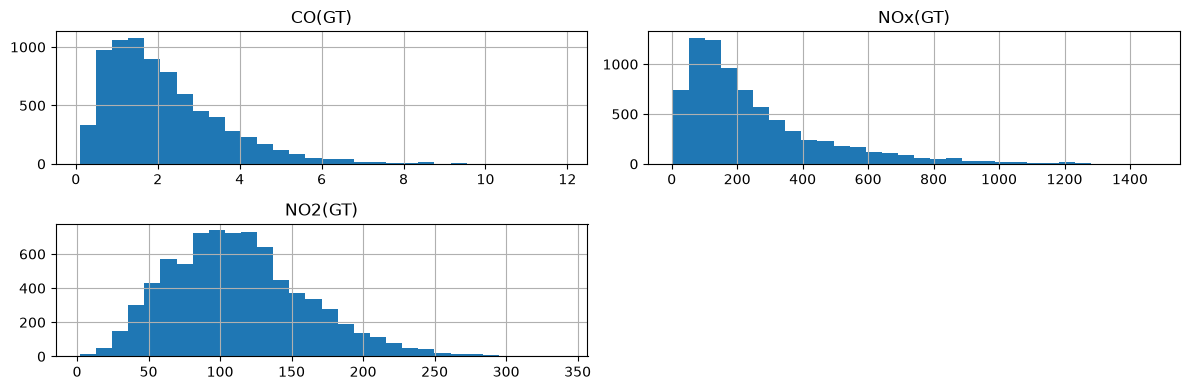

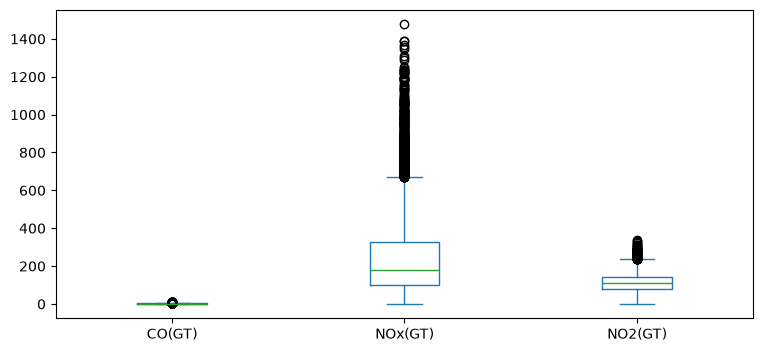

In [10]:
## Si te fijas en los estadísticos del dataset, ¿cómo es la distribución de las variables, CO, NOx y NO2?

contaminantes = ["CO(GT)", "NOx(GT)", "NO2(GT)"]
print(df[contaminantes].describe())
print("Valores faltantes:\n", df[contaminantes].isna().sum())
df[contaminantes].hist(bins=30, figsize=(12,4))
plt.tight_layout(); plt.show()
df[contaminantes].plot(kind="box", figsize=(9,4)); plt.show()

La variable CO(GT) presenta una media de 2.15 mg/m³ y una mediana de 1.80 mg/m³, lo que sugiere una distribución con asimetría positiva, donde la mayoría de las concentraciones se agrupan en valores relativamente bajos. Su desviación estándar es de 1.45 mg/m³ y alcanza un máximo de 11.90 mg/m³, lo que indica la presencia de posibles valores atípicos.

Por su parte, NOx(GT) presenta una media de 246.90 ppb y una mediana de 180 ppb, con una desviación estándar de 212.98 ppb. Estos resultados sugieren una distribución asimétrica hacia la derecha y una elevada variabilidad en las concentraciones registradas, con valores máximos que alcanzan 1479 ppb.

Finalmente, NO2(GT) presenta una media de 113.09 µg/m³ y una mediana de 109 µg/m³, con una desviación estándar de 48.37 µg/m³. La proximidad entre la media y la mediana sugiere una distribución menos asimétrica que las anteriores, aunque también se observan valores elevados que podrían corresponder a observaciones atípicas.

En general, las tres variables presentan diferentes niveles de dispersión y posibles valores extremos. Las distribuciones de CO y NOx muestran indicios más marcados de asimetría positiva, mientras que NO2 presenta una distribución relativamente más equilibrada.

_indica aquí tu respuesta_

¿Estas variables muestran alguna distribución especial?¿Tienen datos faltantes?¿y datos anómalos?

_indica aquí tu respuesta_

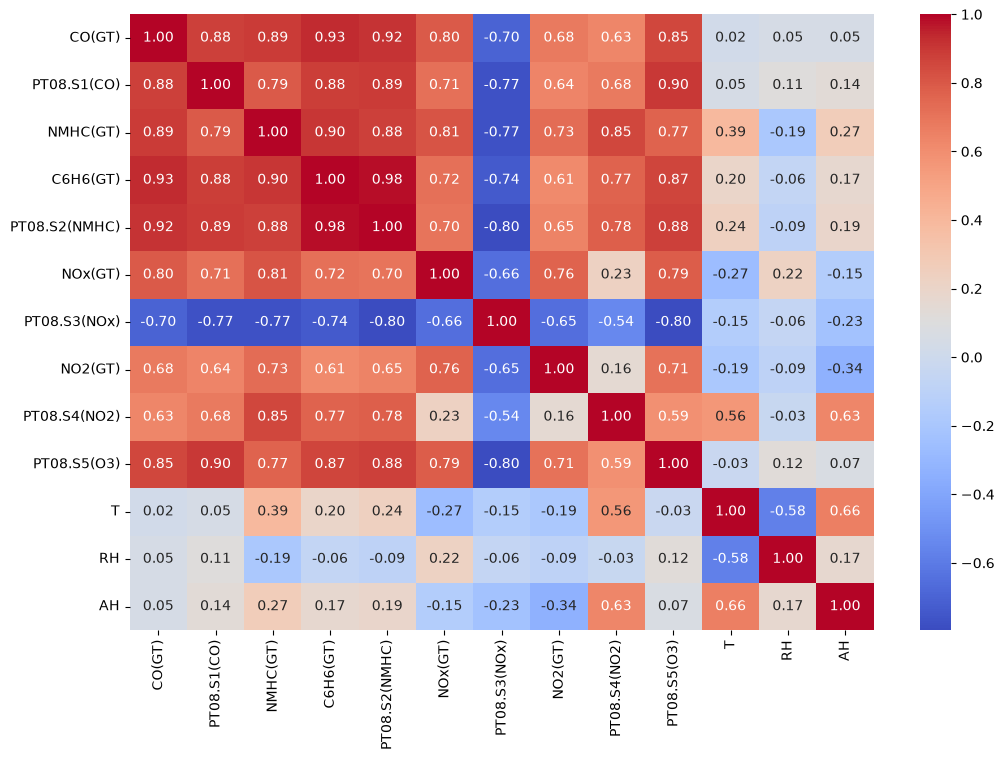

In [11]:
## ¿cómo son las correlaciones entre las variables del dataset?

correlacion = df.corr(numeric_only=True)
plt.figure(figsize=(12,8))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

Se realizó un análisis de correlación entre las variables numéricas, utilizando el coeficiente de correlación de Pearson.

Este análisis permite identificar la intensidad y dirección de las relaciones lineales entre las concentraciones de contaminantes atmosféricos, las respuestas de los sensores y las condiciones ambientales.

Entre las correlaciones positivas más destacadas se encuentra la relación entre C6H6(GT) y PT08.S2(NMHC), con un coeficiente de 0.98, lo que indica una relación lineal positiva muy fuerte. Asimismo, la variable CO(GT) presenta correlaciones elevadas con C6H6(GT) (0.93), PT08.S2(NMHC) (0.92) y NMHC(GT) (0.89), lo que sugiere que estas variables tienden a aumentar conjuntamente.

Respecto a las correlaciones negativas, se destacan las relaciones entre PT08.S2(NMHC) y PT08.S3(NOx) (-0.80), así como entre CO(GT) y PT08.S3(NOx) (-0.70). Estos valores indican relaciones inversas, donde el aumento de una variable tiende a asociarse con la disminución de la otra.


_indica aquí tu respuesta_

In [12]:
## ¿qué tres variables son las más correlacionadas con la variable objetivo?
corr_obj = correlacion[objetivo].drop(index=objetivo).dropna()
top_3 = corr_obj.abs().sort_values(ascending=False).head(3)
print(top_3)

C6H6(GT)         0.931078
PT08.S2(NMHC)    0.915514
NMHC(GT)         0.889734
Name: CO(GT), dtype: float64


_indica aquí tu respuesta_

In [ ]:
La variable C6H6(GT), correspondiente a la concentración de benceno, presenta la correlación más elevada, con un coeficiente de 0.931078, lo que indica una relación lineal positiva muy fuerte con la concentración de monóxido de carbono.

En segundo lugar, se encuentra PT08.S2(NMHC), correspondiente a la respuesta del sensor de hidrocarburos no metánicos, con una correlación de 0.915514, que también representa una relación lineal positiva muy fuerte.

Finalmente, NMHC(GT), correspondiente a la concentración de hidrocarburos no metánicos, presenta una correlación de 0.889734, lo que indica una relación positiva fuerte.

In [13]:
## ¿existe alguna variable que no tenga correlación?
print(corr_obj.abs().sort_values().head(5))

T               0.022109
AH              0.048556
RH              0.048890
PT08.S4(NO2)    0.630703
NO2(GT)         0.683343
Name: CO(GT), dtype: float64


_indica aquí tu respuesta_

In [ ]:
Según la matriz de correlación de Pearson, las variables temperatura (`T`), humedad relativa (`RH`) y humedad absoluta (`AH`) presentan correlaciones muy débiles con `CO(GT)`, con valores aproximados de 0.02, 0.05 y 0.05, respectivamente. Esto indica que no existe una relación lineal significativa en magnitud con la variable objetivo. Sin embargo, podrían existir relaciones no lineales que el coeficiente de Pearson no permite identificar.

En base al EDA realizado, ¿qué suposiciones se pueden hacer sobre los datos?¿qué conclusiones extraes para implementar el modelo predictivo?

> **Orientación paso a paso:** **Paso 11 — Redacta:** resume calidad de datos, faltantes, variables predictoras, relaciones y decisiones para el modelado.

_indica aquí tu respuesta_

### Regresión

Para llevar a cabo la tarea de regresión deseada se pretender hacer una comparativa de varios modelos. Unos usarán el algoritmo de regresión lineal, y otros realizarán la predicción haciendo uso de árboles de decisión.

Para los primeros modelos hay que usar el módulo https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

El algoritmo de Regresión Lineal, necesita saber cuáles son las variables que va a tener en cuenta para realizar la estimación.

El primer modelo que se debe construir, usará una regresión lineal simple. Para ello sigue los siguientes pasos.

Antes de empezar con la implementación de los modelos hace falta realizar una transformación de datos, escalarlos.

In [14]:
# Paso 12: primero separar entrenamiento/prueba, DESPUÉS imputar y escalar.
# Se conserva esta celda en la ubicación original para evitar fuga de información.
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

X = df.select_dtypes(include="number").drop(columns=[objetivo])
y = df[objetivo]
validos = y.notna()
X, y = X.loc[validos], y.loc[validos]
# Nota: al ser una serie temporal, una división cronológica también es recomendable.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
imputador = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputador.fit_transform(X_train_raw),
                       columns=X.columns, index=X_train_raw.index)
X_test = pd.DataFrame(imputador.transform(X_test_raw),
                      columns=X.columns, index=X_test_raw.index)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train),
                              columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test),
                             columns=X.columns, index=X_test.index)
print("Entrenamiento:", X_train.shape, "Prueba:", X_test.shape)

Entrenamiento: (6139, 12) Prueba: (1535, 12)


In [ ]:
# Paso 12 completado en la celda anterior. Verifica que entrenamiento y prueba no se mezclen.
print(len(X_train), len(X_test))

In [ ]:
# Paso 13: elegir predictor con mayor correlación absoluta
variable_simple = top_3.index[0]
print("Predictor elegido:", variable_simple)

In [ ]:
# Paso 13: entrenar regresión simple
from sklearn.linear_model import LinearRegression
modelo_simple = LinearRegression()
modelo_simple.fit(X_train_scaled[[variable_simple]], y_train)

In [ ]:
# Paso 14: parámetros del modelo (predictor estandarizado)
print("Intercepto:", modelo_simple.intercept_)
print("Coeficiente:", modelo_simple.coef_[0])

Explica qué indican estos parámetros

> **Orientación paso a paso:** **Paso 14 — Redacta:** el intercepto es la predicción cuando la variable estandarizada vale 0; el coeficiente es el cambio esperado por una desviación estándar de la variable.

_indica aquí tu respuesta_

In [ ]:
# Paso 15: predicciones de prueba
pred_simple = modelo_simple.predict(X_test_scaled[[variable_simple]])
print(pred_simple[:5])

In [ ]:
# Paso 16: justificar en la respuesta por qué MAE es interpretable en unidades del objetivo
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_log_error

> **Orientación paso a paso:** **Paso 16 — Redacta:** MAE es fácil de interpretar porque expresa el error medio en unidades de CO; también puedes comentar R².

_indica aquí tu respuesta_

In [ ]:
# Paso 16: evaluar regresión simple
mae_simple = mean_absolute_error(y_test, pred_simple)
r2_simple = r2_score(y_test, pred_simple)
print("MAE simple:", mae_simple, "R² simple:", r2_simple)

> **Orientación paso a paso:** **Paso 16 — Redacta:** inserta los valores obtenidos e interpreta el tamaño del error; no copies cifras de ejemplo.

_indica aquí tu respuesta_

Ahora debes entrenar un segundo modelo que haga uso de una regresión lineal múltiple con **todas las variables** del dataset. Después de entrenar, realiza las predicciones para este segundo modelo.

In [ ]:
# Paso 17: entrenar regresión múltiple
modelo_multiple = LinearRegression()
modelo_multiple.fit(X_train_scaled, y_train)

In [ ]:
# Paso 17: predecir con regresión múltiple
pred_multiple = modelo_multiple.predict(X_test_scaled)

In [ ]:
# Paso 18: evaluar y comparar
mae_multiple = mean_absolute_error(y_test, pred_multiple)
r2_multiple = r2_score(y_test, pred_multiple)
print("MAE múltiple:", mae_multiple, "R² múltiple:", r2_multiple)

¿Qué error tiene este modelo?¿Es mejor o peor que el anterior?

> **Orientación paso a paso:** **Paso 18 — Redacta:** compara MAE y R² simple frente a múltiple, y explica si añadir variables ayudó.

_indica aquí tu respuesta_

> **Orientación paso a paso:** **Paso 19 — Completa los huecos originales:** `criterion` mide calidad de división; `splitter` selecciona divisiones; `max_depth` limita profundidad; `min_samples_split` controla mínimo para dividir; `min_samples_leaf` controla mínimo por hoja; `max_features` limita variables consideradas; `min_impurity_decrease` exige una mejora mínima para dividir.

#### Regresión con árboles de decisión

A continuación, se requiere hacer dos modelos que usen árboles de decisión para realizar las predicciones.

Para los árboles de decisión, al ser una tarea de regresión, hay que usar el módulo https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html

El algoritmo **DTRegressor** necesita ajustar una serie de hiperparámetros para realizar las predicciones. La implementación de sklearn nos da mucha flexibilidad para nuestros modelos. En general, para los problemas más comunes de regresión, nos tenemos que preocupar de los siguientes hiperparámetros:

* criterion
* splitter
* max_depth
* min_samples_split
* min_samples_leaf
* max_features

**Indica qué son cada uno de estos hiperparámetros**

_indica aquí tu respuesta_

Además de los hiperparámetros que acabas de descubrir, la implementación de sklearn tiene el hiperparámetro min_impurity_decrease

¿Qué indica ese parámetro? ¿Para qué puede ser útil?

_indica aquí tu respuesta_

Entrena un modelo de árboles de decisión donde, el criterio para realizar las particiones sea _poisson_, la profundidad máxima de los árboles debe ser 10, el número mínimo de ejemplos para realizar una partición debe ser 10, el número mínimo de ejemplos para considerarlo una hoja debe ser 2, y el número máximo de características deben ser todas.

In [ ]:
# Paso 20: árbol de decisión con los hiperparámetros del enunciado
from sklearn.tree import DecisionTreeRegressor
assert y_train.min() >= 0 and y_train.sum() > 0, "Poisson requiere objetivo no negativo y suma positiva"
modelo_arbol = DecisionTreeRegressor(
    criterion="poisson", max_depth=10, min_samples_split=10,
    min_samples_leaf=2, max_features=None, random_state=42)
modelo_arbol.fit(X_train, y_train)

In [ ]:
# Paso 20: predicciones del árbol (sin escalar)
pred_arbol = modelo_arbol.predict(X_test)

Calcula MAE, R2 y RMSLE

In [ ]:
# Paso 21: métricas del árbol
mae_arbol = mean_absolute_error(y_test, pred_arbol)
r2_arbol = r2_score(y_test, pred_arbol)
# RMSLE solo está definido para valores no negativos.
assert (y_test >= 0).all() and (pred_arbol >= 0).all()
rmsle_arbol = np.sqrt(mean_squared_log_error(y_test, pred_arbol))
print("MAE:", mae_arbol, "R²:", r2_arbol, "RMSLE:", rmsle_arbol)

> **Orientación paso a paso:** **Paso 22 — Redacta:** compara MAE de entrenamiento y prueba; una brecha grande puede indicar sobreajuste.

¿Existe overfitting? Indica qué debes hacer para comprobar si hay overfitting.

In [ ]:
# Paso 22: detectar sobreajuste comparando entrenamiento y prueba
pred_train_arbol = modelo_arbol.predict(X_train)
print("MAE train:", mean_absolute_error(y_train, pred_train_arbol))
print("MAE test:", mae_arbol)

¿Este modelo es mejor, peor o igual que los de regresión lineal simple y múltiple? Razona tu respuesta.

> **Orientación paso a paso:** **Paso 23 — Redacta:** compara árbol, simple y múltiple con métricas del mismo conjunto de prueba.

_indica aquí tu respuesta_

> **Orientación paso a paso:** **Paso 24 — Redacta:** elige el mejor modelo con MAE, R², sobreajuste y coste computacional; evita declarar ganador sin resultados.

**Comparativa**

En base al EDA realizado, a las decisiones tomadas sobre los datos e hiperparámetros y a las características computacionales de tu equipo. ¿Qué modelo obtiene mejores resultados de regresión?

In [ ]:
# Paso 23-24: tabla comparativa
resultados = pd.DataFrame({
    "Modelo": ["Regresión simple", "Regresión múltiple", "Árbol de decisión"],
    "MAE": [mae_simple, mae_multiple, mae_arbol],
    "R²": [r2_simple, r2_multiple, r2_arbol]
})
display(resultados)

In [ ]:
# Paso 24: comparar visualmente el MAE
sns.barplot(data=resultados, x="Modelo", y="MAE")
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

> **Orientación paso a paso:** **Pasos 25–26 — Investigación:** busca en Google Académico un artículo de revista posterior a 2015, con regresión lineal o árboles de decisión para regresión y sin deep learning. Añade referencia APA verificable, problema real, técnica, adaptaciones y resultados. **Entrega:** ejecuta todas las celdas desde cero, verifica gráficas y declara el uso de IA según las normas de la asignatura.

## Investigación

Buscar un artículo científico (https://scholar.google.es/) con un caso de uso de **regresión** empleando una de las dos técnicas (o ambas) vistas en la actividad. Los artículos deben estar en revistas científicas, y deben ser posteriores a 2015. No debe utilizar técnicas de Deep Learning.

_introduce aquí la referencia APA del artículo_

título, autores, revista, año de publicación

Deberás detallar cuál es el **objetivo** de la investigación, es decir a qué problema real está aplicando la regresión. **Técnicas de regresión** empleadas y si se realiza alguna adaptación. Principales **resultados** de la aplicación y de la investigación.

In [ ]:
# Paso 25-26: investigación bibliográfica. No se requiere código.
# Completa en una celda Markdown: referencia APA, objetivo, técnicas, adaptaciones y resultados.